# 02 Temporal comparison

Compare regional totals and service composition between 2018 and 2023. Only two observations are available, so this is a two-point comparison rather than a trend model.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.portfolio_analysis import load_data

DATA_PATH = ROOT / 'data' / 'processed' / 'ecosystem_values_2018_2023.csv'
data = load_data(DATA_PATH)
data.head()


,year,county,county_zh,service,service_label,service_zh,value_yuan,value_cny_100m
0,2018,Lushi County,卢氏,provisioning,Provisioning,供给,1.483245e+08,1.483245
1,2018,Lushi County,卢氏,water_retention,Water retention,水源,4.501880e+07,0.450188
2,2018,Lushi County,卢氏,carbon_storage,Carbon storage,碳储,1.394797e+09,13.947970
3,2018,Lushi County,卢氏,soil_retention,Soil retention,土保,4.041572e+09,40.415718
4,2018,Lushi County,卢氏,recreation,Recreation,旅游,4.243289e+09,42.432886


In [2]:
from src.portfolio_analysis import regional_totals, service_summary, validate_data

validate_data(data)
totals = regional_totals(data)
services = service_summary(data)

regional_change = (totals.loc[totals['year'].eq(2023), 'total_cny_100m'].iloc[0] /
                   totals.loc[totals['year'].eq(2018), 'total_cny_100m'].iloc[0] - 1) * 100
print(f'Regional change: {regional_change:.2f}%')


Regional change: 22.44%


In [3]:
service_wide = services.pivot(index='service', columns='year', values='value_cny_100m')
service_wide['change_pct'] = (service_wide[2023] / service_wide[2018] - 1) * 100
service_wide['share_2023_pct'] = services.loc[services['year'].eq(2023)].set_index('service')['share_pct']
service_wide.round(2)


year,2018,2023,change_pct,share_2023_pct
service,,,,
provisioning,101.47,101.62,0.14,3.77
water_retention,12.47,18.24,46.24,0.68
carbon_storage,310.34,316.10,1.86,11.72
soil_retention,718.86,921.24,28.15,34.17
recreation,1058.74,1338.84,26.46,49.66


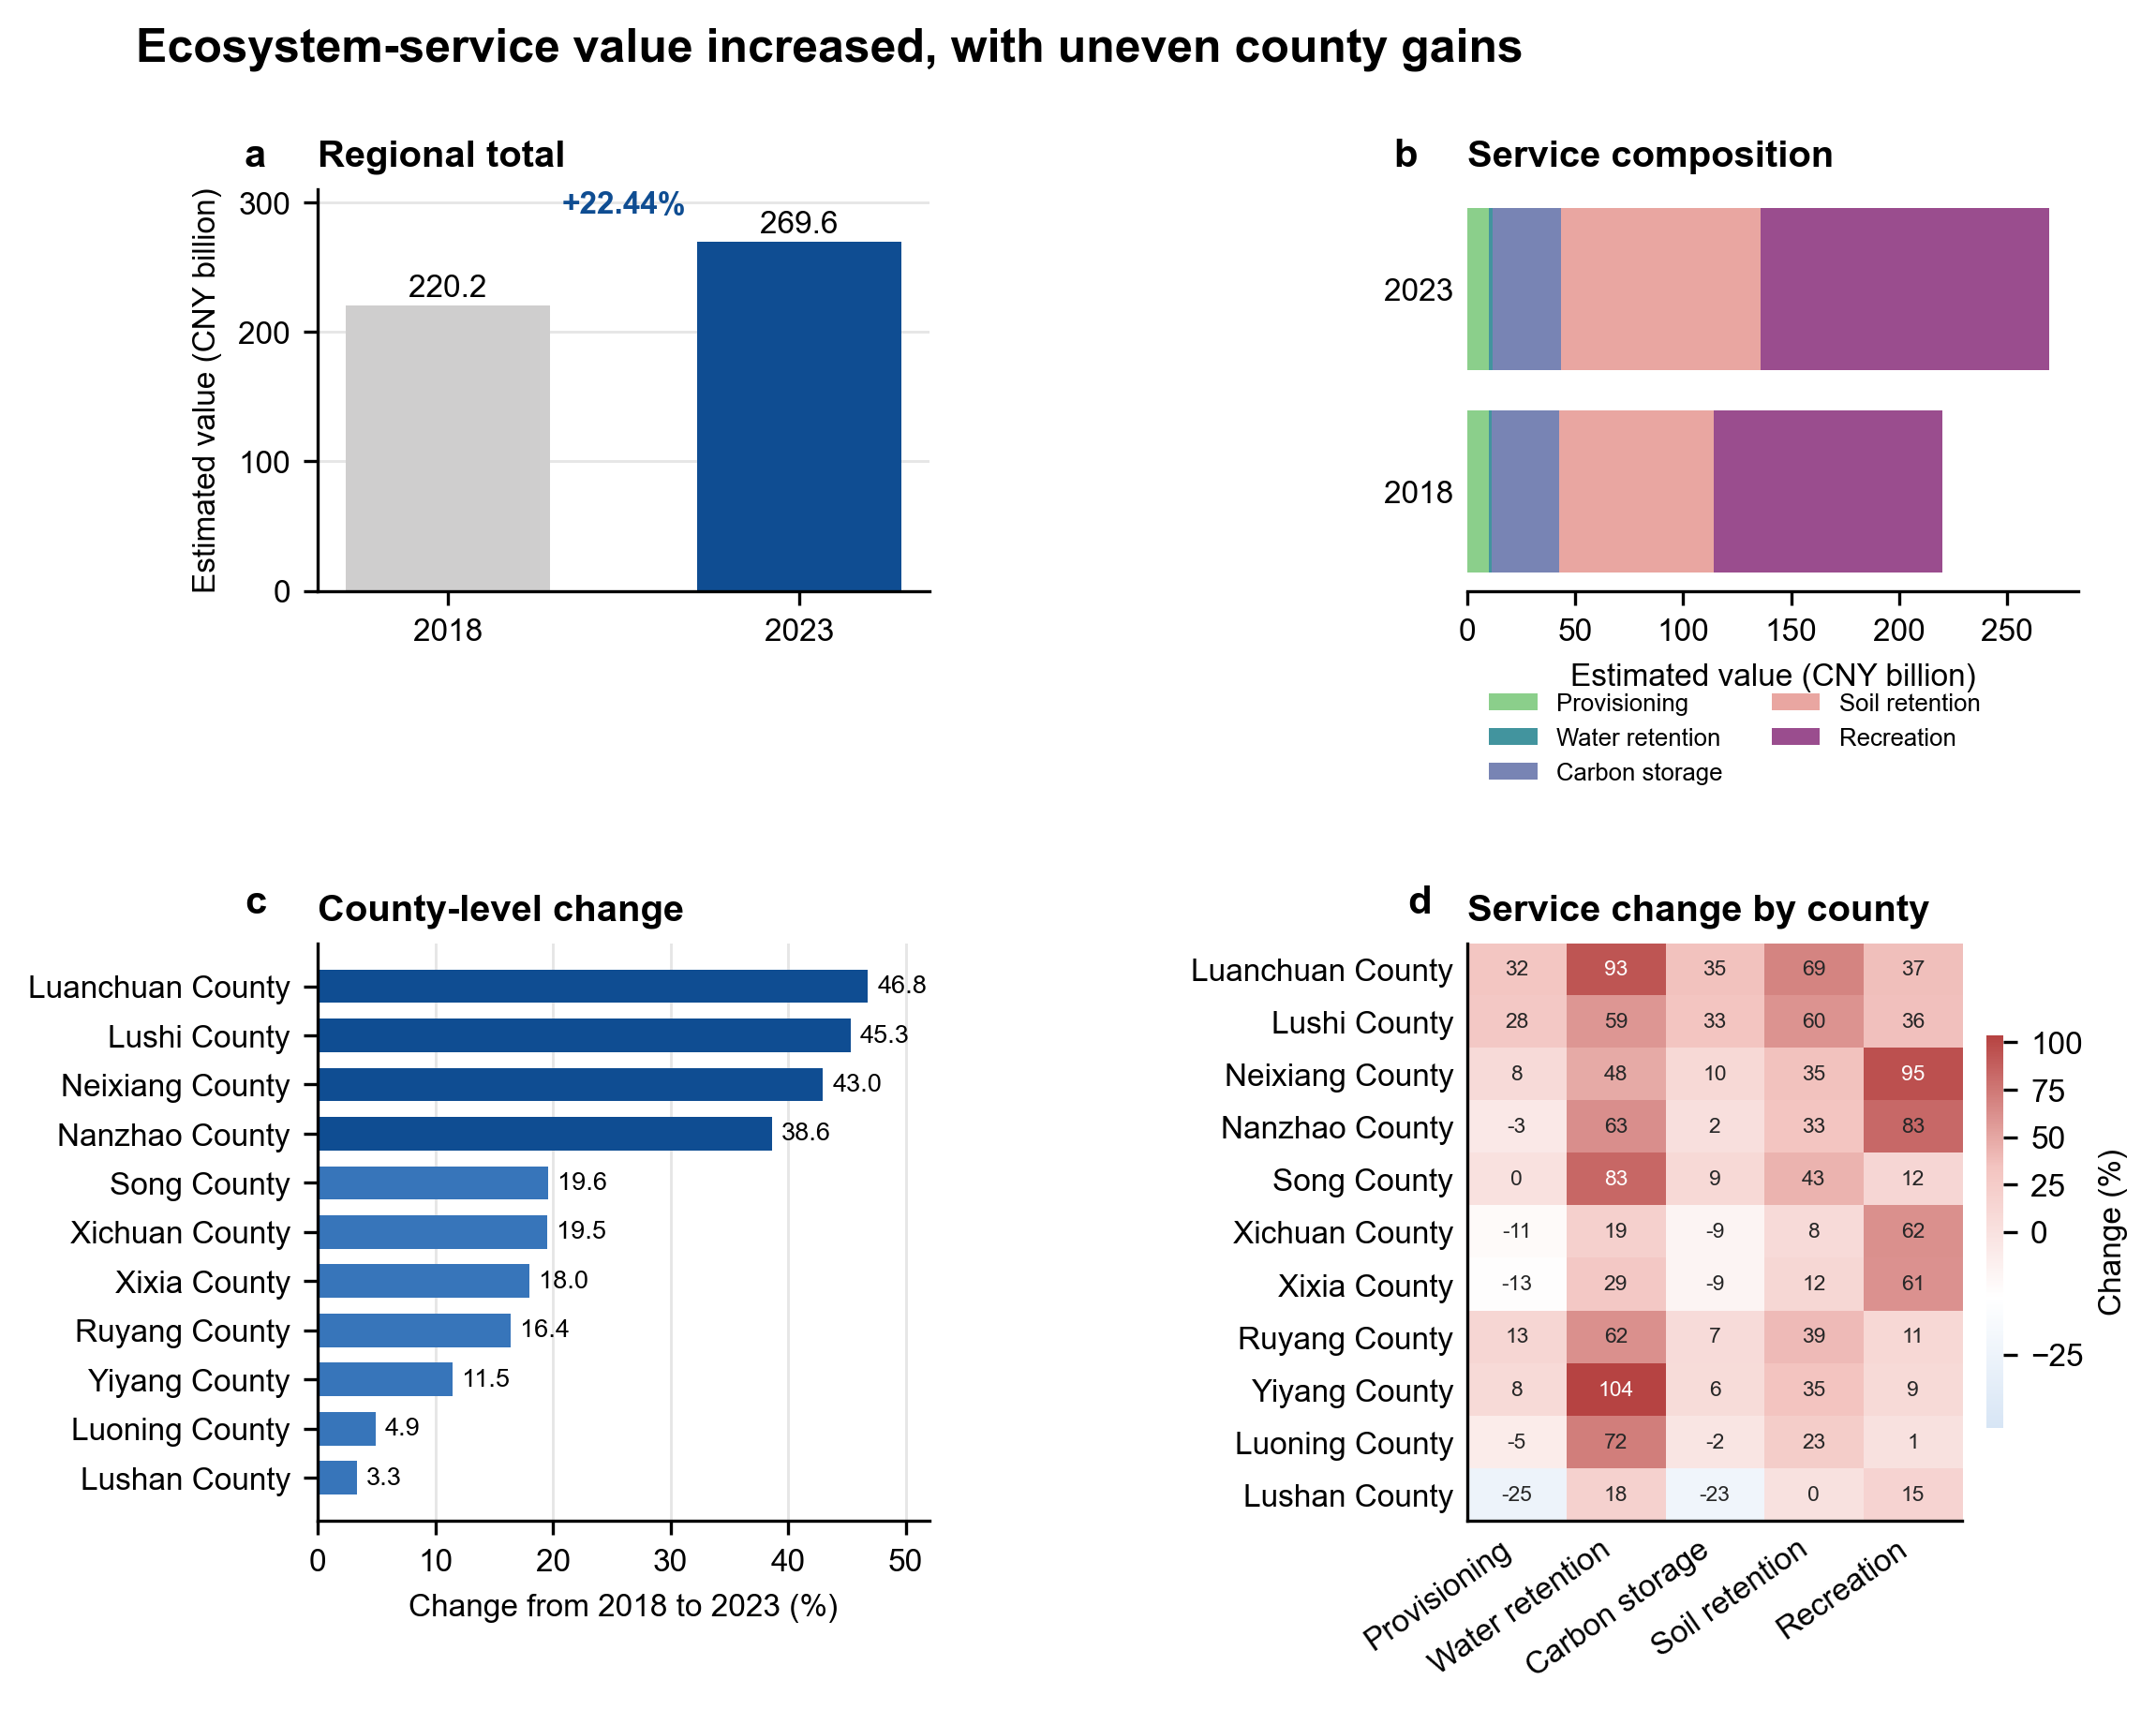

In [4]:
from IPython.display import Image, display
from src.visualization import create_portfolio_figure

output_base = ROOT / 'outputs' / 'charts' / 'portfolio_overview'
create_portfolio_figure(data, output_base)
display(Image(filename=str(output_base.with_suffix('.png'))))
